# Step 6 — paper1's 86 variables re-encoded (no information added), CatBoost and an ensemble

**Question:** with the same variables, can better encoding (plus CatBoost and an ensemble) beat the paper? Variants fixed before running; all are reported.

**Feature tables**

- **raw:** the paper's table as it is (step 3)
- **recoded:** the same variables, re-encoded (`nhanes.paper1.recoded_table`):
  1. numerical fields the paper filled with 0 (mostly skipped questions: no diagnosis, never used, …) are −1 = not applicable / unknown instead, so "0" no longer mixes "none" with "not asked"; weight, height and BMI keep NaN instead of the median
  2. the 13 ages at onset become years since onset (age − onset age, ≥ 0), −1 without the condition
  3. RXDDRUG (name of the first non-antidepressant drug, 755 names) becomes its Multum level-1 drug class (18 classes), "none" without a prescription

**Models:** logreg and xgboost as in step 1, catboost as in step 2, and ensemble = mean of the three probabilities.

**Evaluations**

- **loco:** our 33,498 people, leave-one-cycle-out, inner LOCO over the 6 training cycles
- **kfold10:** the paper's 36,259 people and split (StratifiedKFold(10, shuffle, seed 42)); tuning by an inner 3-fold stratified split of the training folds; survey weights are not available for the extra people, so the weighted AUROC is unweighted there

`WITH_VAE = True` also adds the 32 latent means of step 5's denoising VAE, trained per split on the training rows only (output directory gets a `_vae` suffix).

**Inputs** (with `RUN`): `PAPER1_REPRO` = the folder of our paper1 reproduction that holds `build_dataset.py`; `PAPER1_CSV` = its `FullData_rm_dl_bt.csv`; the Multum drug file (`$NHANES_DATA/RXQ_DRUG.xpt` by default).
**Output:** `$NHANES_WORK/modeling/step6_paper1_recoded/<eval>_<table>/` (`metrics.csv`, `predictions.csv.gz`, `chosen_params.json`, `report.txt`); the recoded table in `.../data/`

`RUN = True` retrains (several hours for all four combinations); `QUICK = True` with it runs one split with the smallest grids. `RUN = False` only shows the saved results.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import DRUG_FILE, RESULTS  # noqa: E402

RUN = False     # True: retrain and overwrite $NHANES_WORK/modeling/step6_paper1_recoded/...
QUICK = False   # with RUN: one split, smallest grids
EVALS = ["loco", "kfold10"]
TABLES = ["raw", "recoded"]
WITH_VAE = False  # add step 5's VAE latent features
PAPER1_REPRO = os.environ.get("PAPER1_REPRO")  # folder with build_dataset.py of the paper1 reproduction
PAPER1_CSV = os.environ.get("PAPER1_CSV")      # its FullData_rm_dl_bt.csv
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step6_paper1_recoded"
MODELS = ["logreg", "xgboost", "catboost"]

## Run

In [2]:
if RUN:
    from nhanes import loco
    from nhanes.loco import (LOGREG_GRID, NOT_FEATURES, XGB_GRID, fit_logreg, fit_xgb, grid, logreg_matrix,
                             metrics, run_catboost, tune)
    from nhanes.paper1 import frames, recoded_table

    def add_vae(f, dic, device, quick):
        """Step 5's denoising VAE, trained on the training rows of this split without labels; adds its
        32 latent means as continuous features."""
        from nhanes.vae import VAE, encode, train_vae
        feats = [c for c in f if c not in NOT_FEATURES]
        is_tr = (f.cycle != "TEST").to_numpy()
        A, B = logreg_matrix(f.loc[is_tr, feats], f.loc[~is_tr, feats], dic)
        vae, epochs, _ = train_vae(A, device, quick)
        z = np.zeros((len(f), VAE["latent"]), dtype=np.float32)
        z[is_tr], z[~is_tr] = encode(vae, A, device), encode(vae, B, device)
        zcols = [f"z{i:02d}" for i in range(VAE["latent"])]
        return (pd.concat([f, pd.DataFrame(z, columns=zcols, index=f.index)], axis=1),
                {**dic, **{c: "continuous" for c in zcols}}, epochs)

    def run(how, table, table_csv, quick, vae=False):
        out = OUT / f"{how}_{table}{'_vae' if vae else ''}"
        if vae:
            import torch
            from nhanes.loco import free_gpu
            gpu = free_gpu()
            device = torch.device(f"cuda:{gpu}" if gpu is not None else "cpu")
            print(f"VAE on {device}", flush=True)
        out.mkdir(parents=True, exist_ok=True)
        grids = {"logreg": grid(LOGREG_GRID), "xgboost": grid(XGB_GRID)}
        if quick:
            grids = {k: v[:1] for k, v in grids.items()}
            loco.CAT_GRID[:] = loco.CAT_GRID[:1]
        preds, rows, chosen = [], [], {}
        for split, f, inner, dic in frames(table_csv, how, quick, PAPER1_CSV):
            if vae:
                t0 = time.time()
                f, dic, epochs = add_vae(f, dic, device, quick)
                print(f"{how} {table} {split} VAE: {epochs} epochs, {(time.time() - t0) / 60:.1f} min", flush=True)
            tr, te = f[f.cycle != "TEST"], f[f.cycle == "TEST"]
            Xtr, Xte = tr.drop(columns=NOT_FEATURES), te.drop(columns=NOT_FEATURES)
            probs = {}
            for model in MODELS:
                t0 = time.time()
                if model == "catboost":
                    prob, params = run_catboost(f, inner, "TEST", dic)
                else:
                    params, inner_auc = tune(model, f, inner, dic, grids[model])
                    if model == "logreg":
                        A, B = logreg_matrix(Xtr, Xte, dic)
                        prob = fit_logreg(A, tr.depression, params).predict_proba(B)[:, 1]
                    else:
                        fit_p = {k: v for k, v in params.items() if k != "n_estimators"}
                        prob = fit_xgb(Xtr, tr.depression, None, None, fit_p,
                                       n_estimators=params["n_estimators"]).predict_proba(Xte)[:, 1]
                    params = {**params, "inner_auroc": round(inner_auc, 4)}
                probs[model] = prob
                chosen[f"{model}|{split}"] = params
                rows.append({"model": model, "split": split, **metrics(te.depression, prob, te.WTMEC2YR),
                             "minutes": round((time.time() - t0) / 60, 1)})
                print(f"{how} {table} {split} {model}: AUROC {rows[-1]['auroc']:.3f}  {params}  {rows[-1]['minutes']} min",
                      flush=True)
            probs["ensemble"] = np.mean([probs[m] for m in MODELS], axis=0)
            rows.append({"model": "ensemble", "split": split, **metrics(te.depression, probs["ensemble"], te.WTMEC2YR),
                         "minutes": 0.0})
            print(f"{how} {table} {split} ensemble: AUROC {rows[-1]['auroc']:.3f}", flush=True)
            preds += [pd.DataFrame({"SEQN": te.SEQN, "split": split, "model": m, "depression": te.depression,
                                    "prob": p}) for m, p in probs.items()]
        met = pd.DataFrame(rows)
        pd.concat(preds, ignore_index=True).to_csv(out / "predictions.csv.gz", index=False)
        met.to_csv(out / "metrics.csv", index=False)
        (out / "chosen_params.json").write_text(json.dumps(chosen, indent=1, default=str))
        summary = met.groupby("model", sort=False)[["auroc", "auroc_weighted", "auprc", "brier"]].agg(["mean", "std"]).round(3)
        lines = [f"features of Dang et al. (2024), table '{table}'{' + VAE latent (step 5)' if vae else ''}, "
                 f"evaluation '{how}'", "",
                 "mean (sd) over test splits:", summary.to_string(), "",
                 "AUROC per test split:", met.pivot(index="split", columns="model", values="auroc").round(3).to_string()]
        (out / "report.txt").write_text("\n".join(lines) + "\n")
        print("\n".join(lines), flush=True)

    rec = OUT / "data" / "FullData_recoded.csv"
    if "recoded" in TABLES and not rec.exists():
        recoded_table(PAPER1_REPRO, PAPER1_CSV, rec, DRUG_FILE)
    tables = {"raw": PAPER1_CSV, "recoded": rec}
    for how in EVALS:
        for table in TABLES:
            run(how, table, tables[table], QUICK, WITH_VAE)

## Results

In [3]:
for name in ["loco_raw", "loco_recoded", "kfold10_raw", "kfold10_recoded"]:
    print(f"===== {name}\n" + (OUT / name / "report.txt").read_text())

===== loco_raw
features of Dang et al. (2024), table 'raw', evaluation 'loco'

mean (sd) over test splits:
          auroc        auroc_weighted         auprc         brier       
           mean    std           mean    std   mean    std   mean    std
model                                                                   
logreg    0.792  0.014          0.796  0.013  0.322  0.033  0.179  0.009
xgboost   0.791  0.013          0.796  0.014  0.316  0.027  0.172  0.007
catboost  0.794  0.013          0.799  0.012  0.325  0.028  0.174  0.008
ensemble  0.796  0.013          0.801  0.013  0.325  0.028  0.174  0.007

AUROC per test split:
model    catboost  ensemble  logreg  xgboost
split                                       
2005-06     0.798     0.805   0.802    0.803
2007-08     0.803     0.803   0.800    0.794
2009-10     0.786     0.787   0.782    0.784
2011-12     0.815     0.818   0.814    0.812
2013-14     0.789     0.790   0.785    0.786
2015-16     0.792     0.791   0.787    0.782

In [4]:
met = pd.concat([pd.read_csv(OUT / f"{h}_{t}" / "metrics.csv").assign(eval=h, table=t)
                 for h in ["loco", "kfold10"] for t in ["raw", "recoded"]], ignore_index=True)
table = met.pivot_table(index=["eval", "table"], columns="model", values="auroc", aggfunc="mean", sort=False)
display(table[["logreg", "xgboost", "catboost", "ensemble"]].round(3))

model            logreg  xgboost  catboost  ensemble
eval    table                                       
loco    raw       0.792    0.791     0.794     0.796
        recoded   0.792    0.794     0.795     0.797
kfold10 raw       0.786    0.786     0.789     0.790
        recoded   0.786    0.788     0.789     0.791

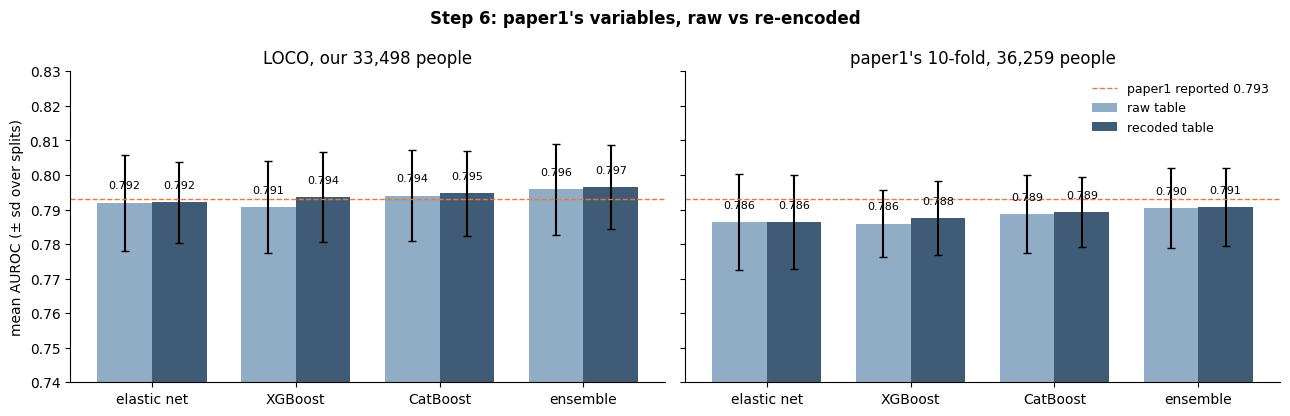

In [5]:
import matplotlib.pyplot as plt  # noqa: E402

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
names = {"logreg": "elastic net", "xgboost": "XGBoost", "catboost": "CatBoost", "ensemble": "ensemble"}
for ax, how, title in [(axes[0], "loco", "LOCO, our 33,498 people"), (axes[1], "kfold10", "paper1's 10-fold, 36,259 people")]:
    sub = met[met["eval"] == how]
    x = np.arange(4)
    for i, (t, color) in enumerate([("raw", "#91ACC5"), ("recoded", "#405B76")]):
        s = sub[sub.table == t].groupby("model").auroc.agg(["mean", "std"]).reindex(list(names))
        ax.bar(x + (i - 0.5) * 0.38, s["mean"], 0.38, yerr=s["std"], capsize=3, color=color, label=f"{t} table")
        for xi, v in zip(x + (i - 0.5) * 0.38, s["mean"]):
            ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", fontsize=8)
    ax.axhline(0.793, color="#E9783D", ls="--", lw=1, label="paper1 reported 0.793")
    ax.set_xticks(x, list(names.values()))
    ax.set_ylim(0.74, 0.83)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("mean AUROC (± sd over splits)")
axes[1].legend(frameon=False, fontsize=9)
fig.suptitle("Step 6: paper1's variables, raw vs re-encoded", fontweight="bold")
plots.show()

`kfold10_recoded_vae/` (the same with step 5's VAE features, `WITH_VAE = True`), if it was run:

In [6]:
vae_dir = OUT / "kfold10_recoded_vae"
print((vae_dir / "report.txt").read_text() if (vae_dir / "report.txt").exists() else "not run")

features of Dang et al. (2024), table 'recoded' + VAE latent (step 5), evaluation 'kfold10'

mean (sd) over test splits:
          auroc     auroc_weighted      auprc      brier    
           mean std           mean std   mean std   mean std
model                                                       
logreg    0.786 NaN          0.786 NaN  0.326 NaN  0.180 NaN
xgboost   0.792 NaN          0.792 NaN  0.329 NaN  0.173 NaN
catboost  0.790 NaN          0.790 NaN  0.329 NaN  0.178 NaN
ensemble  0.792 NaN          0.792 NaN  0.333 NaN  0.176 NaN

AUROC per test split:
model  catboost  ensemble  logreg  xgboost
split                                     
fold0      0.79     0.792   0.786    0.792

